# Forecasting PJM East hourly load

This is the Colab version of `notebooks/pjm_load_forecast_pipeline.ipynb`. It doesn't need
anything from the `ml_pipeline` repo. The cleaning, feature, model and evaluation code is copied
into the cells below with the same settings as `config/pjm_load_forecast/*.yaml`, so you should
get the same numbers as the pipeline run.

The goal is to forecast the next 24 hours of load for the PJM East zone, starting at midnight,
and to see how much hourly weather helps. Six models are compared on the same 50 days:

- repeat yesterday (daily naive) and repeat last week (weekly naive)
- ETS (exponential smoothing)
- LightGBM with weather and LightGBM without weather
- a direct LightGBM that predicts every hour of the day from the data available at midnight

The notebook follows the usual steps: 1. Data Loading, 2. Cleaning & EDA, 3. Modeling,
4. Evaluation, 5. Final Forecast Generation.

What's left out: Airflow, MLflow, pandera schemas, manifest files, the profiling reports and the
FastAPI service. Those are production plumbing and don't change any result.

A full run takes about 10-20 minutes on a normal Colab CPU runtime, a bit longer the first time
because it downloads the data. Figures, CSVs and JSON files are saved to `outputs/`, and the last
cell downloads them as a zip.

### Where each Track 1 requirement is covered

| Requirement | Where |
|---|---|
| Multiple seasonality (daily, weekly, annual) | 2c: ACF spikes at 24h and 168h, the monthly cycle and the seasonal daily shapes. These led to the lag-24/168 features, rolling windows and calendar fields |
| Classical vs. machine learning | ETS against recursive and direct LightGBM on the same cutoffs (3, 4) |
| Honest backtesting | Split by time (80/20), 50 midnight cutoffs with a 24-hour horizon, lag features rebuilt from the model's own predictions after each cutoff (3c, 3d) |
| Baseline comparison | Repeat-yesterday (lag 24) and repeat-last-week (lag 168), scored the same way as every other model (3, 4) |
| Uncertainty | 90% ranges built from validation errors, with coverage checked on the test days (5b) |
| Operational framing | Whether the misses are too high or too low, errors by season and holiday (4), and by hour of day (5b) |

## Setup

Install the packages first. LightGBM and statsmodels are pinned to the versions the pipeline
used, since a different version can shift the numbers slightly. Everything else is already
installed in Colab.

In [ ]:
!pip install lightgbm==4.6.0 statsmodels==0.14.6 scikit-learn kagglehub

In [2]:
import json
import os
import shutil
import sys
import time
import urllib.error
import urllib.parse
import urllib.request
import warnings
from pathlib import Path
from typing import Any

import lightgbm
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
from IPython.display import Markdown, display
from lightgbm import LGBMRegressor
from pandas.tseries.holiday import USFederalHolidayCalendar
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 4)

IN_COLAB = "google.colab" in sys.modules

# Data goes in pjm_data/ and results in outputs/, next to the notebook.
# Set PJM_DATA_DIR / PJM_OUTPUT_DIR to put them somewhere else.
DATA_DIR = Path(os.environ.get("PJM_DATA_DIR", "pjm_data"))
OUTPUT_DIR = Path(os.environ.get("PJM_OUTPUT_DIR", "outputs"))
FIG_DIR = OUTPUT_DIR / "figures"
for directory in (DATA_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"lightgbm {lightgbm.__version__} | statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__}")
print(f"Data dir: {DATA_DIR}/ | outputs: {OUTPUT_DIR}/")

Python 3.12.11 | pandas 3.0.6 | numpy 2.5.4 | lightgbm 4.6.0 | statsmodels 0.14.6 | matplotlib 3.11.2
Data dir: pjm_data/ | outputs: outputs/


## Configuration

Every setting that changes the results is in this one cell. The values are the same as the
pipeline's `config/pjm_load_forecast/*.yaml`. To try something different, change it here and
rerun the notebook from this cell down.

In [3]:
# Same values as config/pjm_load_forecast/*.yaml in the ml_pipeline repo.

# Data and split
TARGET = "PJME_MW"     # the column we forecast: PJM East hourly load in MW
TRAIN_FRACTION = 0.80  # first 80% of hours for training, last 20% for test.
                       # Split by time, never shuffled, so the model never trains on the future.
MAX_GAP_HOURS = 6      # missing stretches up to 6 hours (DST, sensor blips) get interpolated.
                       # Anything longer stops the notebook: filling a multi-day outage would
                       # leave made-up values in the lag features for weeks.

# Weather stations: one airport for each big city in the zone, averaged into one regional series.
# All weights are equal. Raise one to give that city more say in the average.
STATIONS = {
    "PHL": {"latitude": 39.8721, "longitude": -75.2411, "weight": 1.0},  # Philadelphia (PECO)
    "EWR": {"latitude": 40.6925, "longitude": -74.1687, "weight": 1.0},  # Newark (PSE&G / JCP&L)
    "BWI": {"latitude": 39.1754, "longitude": -76.6683, "weight": 1.0},  # Baltimore (BGE)
    "DCA": {"latitude": 38.8512, "longitude": -77.0402, "weight": 1.0},  # Washington DC (Pepco)
}

# Load features (picked from the autocorrelation spikes in the EDA)
LAGS = [1, 24, 168]          # 1 hour ago, same hour yesterday, same hour last week
ROLLING_WINDOWS = [24, 168]  # mean and std over the past day and the past week
SNAPSHOT_HOURS = 168         # hours of real history used to start the final 24h forecast.
                             # Has to cover the longest lag or window (168h).

# Weather features
COMFORT_TEMP_F = 65                 # load is lowest around here. Degrees above it count as
                                    # cooling demand, degrees below it as heating demand.
WEATHER_ROLLING_WINDOWS = [24, 72]  # average temperature over the past 1 and 3 days (heat waves, cold snaps)
WEATHER_PREFIX = "wx_"              # weather columns start with this, so the no-weather model can drop them

# Backtest
HORIZON = 24    # forecast 24 hours ahead from each midnight (day-ahead planning)
N_WINDOWS = 50  # number of days scored in validation and again in test, the same days for every model

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Models
# LightGBM settings are chosen by hand, not tuned, so the comparison is between model types
# rather than between how much tuning each one got.
GBM_PARAMS = {
    "n_estimators": 200,    # number of boosting rounds
    "learning_rate": 0.05,  # small steps; together with 200 rounds this keeps overfitting down
    "max_depth": 7,         # deep enough for hour x season x temperature interactions
    "num_leaves": 31,       # LightGBM's default
    "random_state": SEED,   # same trees every run
    "n_jobs": -1,           # use all CPU cores
}

# All six models are scored on the same cutoffs and horizon. "status" decides their role:
#   baseline  - simple benchmarks every model should beat, never picked as champion
#   candidate - can be picked as champion (lowest validation MAPE wins)
#   benchmark - shown for comparison only
MODELS = [
    # Repeat the same hour from yesterday
    {"name": "daily_naive", "type": "seasonal_naive", "season_length": 24, "status": "baseline"},
    # Repeat the same hour from last week
    {"name": "weekly_naive", "type": "seasonal_naive", "season_length": 168, "status": "baseline"},
    # Classical model: exponential smoothing with additive trend and a 24-hour season
    {"name": "ets", "type": "ets", "status": "candidate"},
    # LightGBM with weather. Predicts one hour at a time and feeds each prediction back in as a lag.
    {"name": "gbm", "type": "gbm", "use_weather": True, "params": GBM_PARAMS, "status": "candidate"},
    # Direct LightGBM: one model that takes the lead hour as an input, trained on a cutoff every
    # 6 hours. Its training set is 24x bigger, so it gets 150 rounds instead of 200.
    {"name": "gbm_direct", "type": "gbm_direct", "use_weather": True, "stride_hours": 6,
     "params": {**GBM_PARAMS, "n_estimators": 150}, "status": "benchmark"},
    # Same as gbm but without the wx_ columns. The gap between the two is what weather is worth.
    {"name": "gbm_no_weather", "type": "gbm", "use_weather": False, "params": GBM_PARAMS, "status": "candidate"},
]

# Meteorological seasons, for breaking the errors down by season
SEASONS = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}

# 1. Data Loading

Two data sources are used.

**Load:** PJM hourly energy consumption from Kaggle. The next cell downloads it with `kagglehub`.
If that doesn't work, you can get it yourself:

1. Go to <https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption> and click
   *Download* (you need a free Kaggle account).
2. Unzip it and find `PJME_hourly.csv`. It has hourly PJM East load from 2002 to 2018, in MW.
3. Put the file in `pjm_data/`. In Colab, open the folder panel on the left and upload it there,
   or just run the cell and it will ask you to upload the file.

**Weather:** the Open-Meteo historical archive
(<https://open-meteo.com/en/docs/historical-weather-api>). It's free and needs no API key. We
pull hourly temperature, dew point, humidity and wind speed at four airports, one for each big
city in the zone: Philadelphia (PHL), Newark (EWR), Baltimore (BWI) and Washington DC (DCA). The
cell asks for one year at a time (about 72 requests, a few minutes) and saves
`pjm_data/weather_hourly.csv`, so later runs skip the download. The data is ERA5 reanalysis, a
model estimate on a grid rather than the airport's own sensor. That smooths out some local
extremes, but it's good enough to capture how load reacts to temperature.

A note on time zones: `PJME_hourly.csv` is in Eastern local time with no UTC offset. The weather
is requested in UTC and converted to the same local clock, so both files have the same repeated
and missing hours around daylight saving changes and get cleaned the same way.

In [4]:
LOAD_CSV = DATA_DIR / "PJME_hourly.csv"

if not LOAD_CSV.exists():
    try:
        import kagglehub
        kaggle_dir = Path(kagglehub.dataset_download("robikscube/hourly-energy-consumption"))
        shutil.copy(kaggle_dir / "PJME_hourly.csv", LOAD_CSV)
    except Exception as err:
        print(f"kagglehub download failed ({err}).")
        if not IN_COLAB:
            raise FileNotFoundError(f"Download PJME_hourly.csv from Kaggle and place it at {LOAD_CSV}") from err
        from google.colab import files
        print("Upload PJME_hourly.csv (Kaggle: robikscube/hourly-energy-consumption).")
        if "PJME_hourly.csv" not in files.upload():
            raise FileNotFoundError("PJME_hourly.csv was not uploaded") from err
        shutil.move("PJME_hourly.csv", LOAD_CSV)

raw_load = pd.read_csv(LOAD_CSV)
print(f"Load: {len(raw_load):,} rows from {LOAD_CSV}")
raw_load.head()

Load: 145,366 rows from pjm_data/PJME_hourly.csv


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [5]:
WEATHER_CSV = DATA_DIR / "weather_hourly.csv"
WEATHER_START, WEATHER_END = pd.Timestamp("2001-12-31"), pd.Timestamp("2018-08-04")  # one day of padding around the load file
OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"
OPEN_METEO_VARIABLES = {"temperature_2m": "temp_f", "dew_point_2m": "dewpoint_f",
                        "relative_humidity_2m": "rel_humidity", "wind_speed_10m": "wind_mph"}


def fetch_open_meteo(params: dict[str, Any], retries: int = 4) -> dict[str, Any]:
    """GET the Open-Meteo archive API, retrying with backoff on HTTP 429/5xx."""
    url = f"{OPEN_METEO_URL}?{urllib.parse.urlencode(params)}"
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=120) as resp:
                return json.loads(resp.read().decode("utf-8"))
        except urllib.error.HTTPError as err:
            if not (err.code == 429 or err.code >= 500) or attempt == retries - 1:
                raise
            time.sleep(30 * (attempt + 1))
    raise RuntimeError("unreachable")


if not WEATHER_CSV.exists():
    frames = []
    for station, info in STATIONS.items():
        for year in range(WEATHER_START.year, WEATHER_END.year + 1):
            chunk_start = max(WEATHER_START, pd.Timestamp(year=year, month=1, day=1))
            chunk_end = min(WEATHER_END, pd.Timestamp(year=year, month=12, day=31))
            hourly = fetch_open_meteo({
                "latitude": info["latitude"], "longitude": info["longitude"],
                "start_date": f"{chunk_start:%Y-%m-%d}", "end_date": f"{chunk_end:%Y-%m-%d}",
                "hourly": ",".join(OPEN_METEO_VARIABLES), "temperature_unit": "fahrenheit",
                "wind_speed_unit": "mph", "timezone": "GMT",
            })["hourly"]
            eastern = pd.to_datetime(hourly["time"]).tz_localize("UTC").tz_convert("America/New_York").tz_localize(None)
            frame = pd.DataFrame({"Datetime": eastern, "station": station})
            for api_name, column in OPEN_METEO_VARIABLES.items():
                frame[column] = pd.to_numeric(pd.Series(hourly[api_name]), errors="coerce").to_numpy()
            frames.append(frame)
            time.sleep(1.0)  # stay inside Open-Meteo's free-tier rate limit
        print(f"Fetched {station}")
    pd.concat(frames, ignore_index=True).sort_values(["station", "Datetime"]).to_csv(WEATHER_CSV, index=False)

raw_weather = pd.read_csv(WEATHER_CSV)
print(f"Weather: {len(raw_weather):,} rows, {raw_weather.station.nunique()} stations, "
      f"{raw_weather.Datetime.min()} to {raw_weather.Datetime.max()}")

Weather: 581,856 rows, 4 stations, 2001-12-30 19:00:00 to 2018-08-04 19:00:00


# 2. Cleaning & EDA

## 2a. First look at the raw load file

A quick summary of what we're starting with.

In [6]:
parsed = pd.to_datetime(raw_load.Datetime)
expected_hours = int((parsed.max() - parsed.min()) / pd.Timedelta(hours=1)) + 1
pd.DataFrame({"value": {
    "rows": f"{len(raw_load):,}",
    "date range": f"{parsed.min()} to {parsed.max()}",
    "sorted by time": bool(parsed.is_monotonic_increasing),
    "unique timestamps": f"{parsed.nunique():,} (expected {expected_hours:,})",
    "duplicated timestamps": int(parsed.duplicated().sum()),
    "missing hours": expected_hours - parsed.nunique(),
    "null values": int(raw_load.isna().sum().sum()),
}})

,value
rows,"145,366"
date range,2002-01-01 01:00:00 to 2018-08-03 00:00:00
sorted by time,False
unique timestamps,"145,362 (expected 145,392)"
duplicated timestamps,4
missing hours,30
null values,0


## 2b. Clean

What the cleaning does and why:

- **Sort by time.** The Kaggle CSV isn't in order.
- **Average duplicate timestamps.** There are 4, all on the November daylight saving change, when
  the same clock hour happens twice. For example `2014-11-02 02:00` shows up as both 23,755 and
  22,935 MW. Both are real readings, so we average them instead of throwing one away.
- **Fill short gaps only.** After reindexing to a full hourly index there are 30 missing hours.
  They're the spring daylight saving hours that never existed. Gaps up to 6 hours are filled by
  linear interpolation. Anything longer stops the notebook, because filling a multi-day outage
  would leave fake values in the lag features for weeks.
- **Build one regional weather series.** The four stations are averaged each hour (if a station
  is missing for an hour, the others are reweighted) and joined as `wx_` columns. The same gap
  rule applies.

In [7]:
RAW_WEATHER_COLUMNS = {"temp_f": "wx_temp_f", "dewpoint_f": "wx_dewpoint_f",
                       "rel_humidity": "wx_rel_humidity", "wind_mph": "wx_wind_mph"}


def fill_short_gaps(series: pd.Series, name: str) -> tuple[pd.Series, list[int]]:
    """Linearly interpolate missing runs up to MAX_GAP_HOURS; raise on anything longer."""
    missing = series.isna()
    gap_lengths: list[int] = []
    if missing.any():
        missing_ts = missing[missing].index.to_series()
        for _, run in missing_ts.groupby((missing_ts.diff() != pd.Timedelta(hours=1)).cumsum()):
            if len(run) > MAX_GAP_HOURS:
                raise ValueError(f"{name}: {len(run)}h gap from {run.iloc[0]} to {run.iloc[-1]} exceeds {MAX_GAP_HOURS}h")
            gap_lengths.append(len(run))
    return series.interpolate(method="linear"), gap_lengths


# Load: sort, average duplicate timestamps, reindex hourly, fill short gaps.
load_sorted = raw_load.assign(Datetime=pd.to_datetime(raw_load.Datetime)).sort_values("Datetime")
deduped = load_sorted.groupby("Datetime", as_index=False)[TARGET].mean().set_index("Datetime")
clean_df = deduped.reindex(pd.date_range(deduped.index.min(), deduped.index.max(), freq="h", name="Datetime"))
clean_df[TARGET], load_gaps = fill_short_gaps(clean_df[TARGET], TARGET)

# Weather: average repeated DST hours per station, then a weighted regional mean per hour.
weather = raw_weather.assign(Datetime=pd.to_datetime(raw_weather.Datetime))
weather = weather[weather.station.isin(STATIONS)]
weather = weather.groupby(["Datetime", "station"], as_index=False)[list(RAW_WEATHER_COLUMNS)].mean()
weights = weather.station.map({k: v["weight"] for k, v in STATIONS.items()}).astype(float)
regional = {}
for raw_col, wx_col in RAW_WEATHER_COLUMNS.items():
    valid = weather[raw_col].notna()
    numerator = (weather[raw_col] * weights).where(valid).groupby(weather.Datetime).sum(min_count=1)
    denominator = weights.where(valid).groupby(weather.Datetime).sum(min_count=1)
    regional[wx_col] = numerator / denominator
regional = pd.DataFrame(regional).sort_index().reindex(clean_df.index)
for col in regional.columns:
    regional[col], _ = fill_short_gaps(regional[col], col)
clean_df = clean_df.join(regional)

assert clean_df.index.is_unique and clean_df.index.is_monotonic_increasing and not clean_df.isna().any().any()
print(f"Cleaned: {len(clean_df):,} rows, {len(load_sorted) - len(deduped)} duplicates averaged, "
      f"{len(load_gaps)} gap(s) filled ({sum(load_gaps)} hours)")

Cleaned: 145,392 rows, 4 duplicates averaged, 30 gap(s) filled (30 hours)


## 2c. EDA: what shaped the model

Only the first 80% of the data (the training part) is used here, so nothing about the test
period influences the modeling choices.

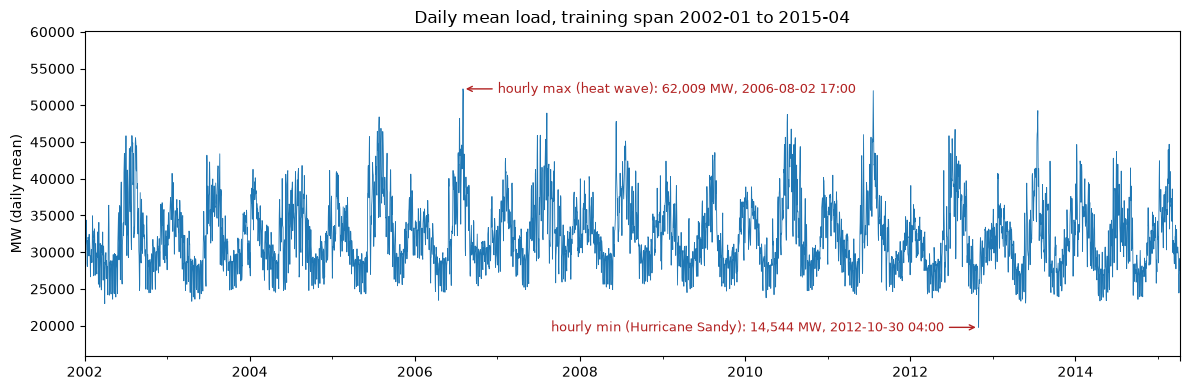

Annual mean load: 31,564 MW in 2002, 31,497 MW in 2014 (range 31,439-34,200 MW)


In [8]:
eda = clean_df.iloc[: int(len(clean_df) * TRAIN_FRACTION)]
load = eda[TARGET]
daily = load.resample("D").mean()
fig, ax = plt.subplots(figsize=(12, 4))
daily.plot(ax=ax, linewidth=0.6)
ax.set_ylim(daily.min() * 0.8, daily.max() * 1.15)
for ts, label, offset, ha in ((load.idxmax(), "max (heat wave)", (25, 0), "left"),
                              (load.idxmin(), "min (Hurricane Sandy)", (-25, 0), "right")):
    ax.annotate(f"hourly {label}: {load[ts]:,.0f} MW, {ts:%Y-%m-%d %H:%M}", xy=(ts, daily[ts.normalize()]),
                xytext=offset, textcoords="offset points", va="center", ha=ha,
                arrowprops=dict(arrowstyle="->", color="firebrick"), color="firebrick", fontsize=9)
ax.set(xlabel="", ylabel="MW (daily mean)", title=f"Daily mean load, training span {eda.index.min():%Y-%m} to {eda.index.max():%Y-%m}")
plt.tight_layout()
plt.show()

yearly = load.groupby(load.index.year).mean()
print(f"Annual mean load: {yearly.iloc[0]:,.0f} MW in {yearly.index[0]}, {yearly.iloc[-2]:,.0f} MW in {yearly.index[-2]} "
      f"(range {yearly.min():,.0f}-{yearly.max():,.0f} MW)")

**Outliers are real events, so they stay.** The highest load in training (2 Aug 2006) was a
heat wave, and the lowest (30 Oct 2012) was Hurricane Sandy knocking out power across the zone.
Those are exactly the kind of days a grid operator has to plan for, so removing them would be a
mistake. The yearly average barely moves, so the model doesn't need a strong trend term. LightGBM
still gets a `year` feature to pick up slow drift.

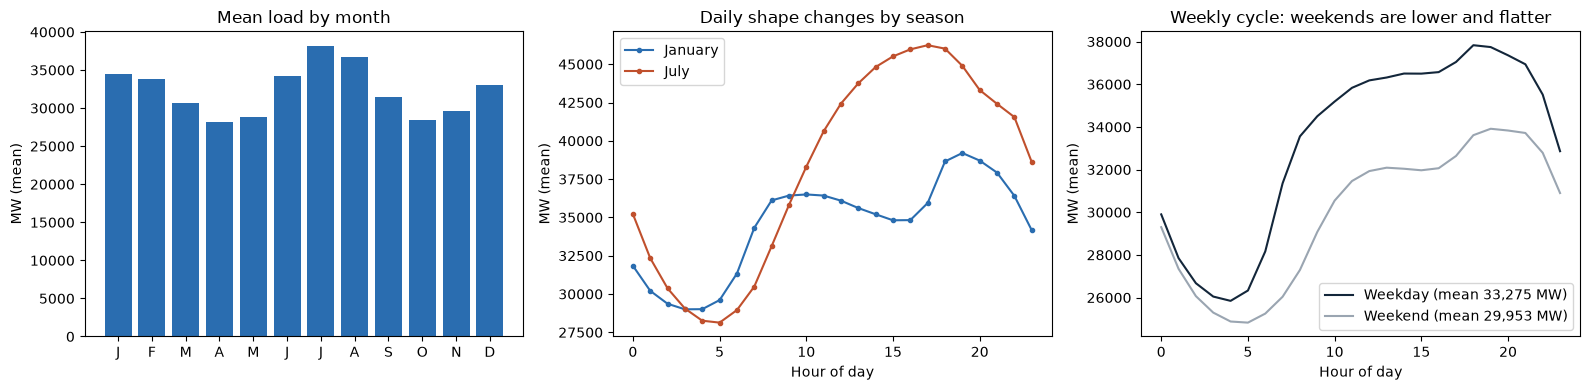

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
monthly = load.groupby(load.index.month).mean()
axes[0].bar(monthly.index, monthly.values, color="#2a6db0")
axes[0].set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"), ylabel="MW (mean)", title="Mean load by month")

for month, color in ((1, "#2a6db0"), (7, "#c0502d")):
    profile = load[load.index.month == month]
    profile.groupby(profile.index.hour).mean().plot(ax=axes[1], color=color, marker="o", ms=3,
                                                    label=pd.Timestamp(2000, month, 1).strftime("%B"))
axes[1].set(xlabel="Hour of day", ylabel="MW (mean)", title="Daily shape changes by season")
axes[1].legend()

weekend = load.index.dayofweek >= 5
for mask, label, color in ((~weekend, "Weekday", "#13263a"), (weekend, "Weekend", "#9aa5b1")):
    part = load[mask]
    part.groupby(part.index.hour).mean().plot(ax=axes[2], label=f"{label} (mean {part.mean():,.0f} MW)", color=color)
axes[2].set(xlabel="Hour of day", ylabel="MW (mean)", title="Weekly cycle: weekends are lower and flatter")
axes[2].legend()
plt.tight_layout()
plt.show()

**There are three seasonal cycles at once.** Over the year there are two peaks: a big one in
summer from air conditioning and a smaller one in winter from heating. The shape of the day also
changes with the season. January has a morning and an evening peak, while July has one sharp
peak in the late afternoon, so a single fixed daily profile would miss the summer peak. Weekends
are lower and flatter than weekdays.

That's why LightGBM gets `hour`, `day_of_week`, `month`, `is_weekend` and holiday features and
can learn how they interact. It's also why ETS, which only handles one 24-hour season, is
expected to struggle.

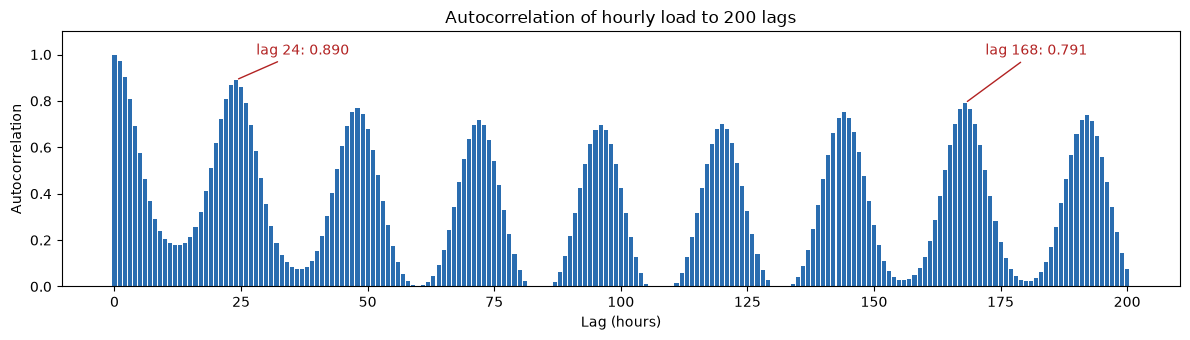

ACF lag 1 0.974 | lag 24 0.890 | lag 168 0.791


In [10]:
acf_values = acf(load, nlags=200, fft=True)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(range(len(acf_values)), acf_values, width=0.8, color="#2a6db0")
for lag in (24, 168):
    ax.annotate(f"lag {lag}: {acf_values[lag]:.3f}", xy=(lag, acf_values[lag]), xytext=(lag + 4, 1.0), color="firebrick",
                arrowprops=dict(arrowstyle="-", color="firebrick"))
ax.set(xlabel="Lag (hours)", ylabel="Autocorrelation", title="Autocorrelation of hourly load to 200 lags", ylim=(0, 1.1))
plt.tight_layout()
plt.show()
print(f"ACF lag 1 {acf_values[1]:.3f} | lag 24 {acf_values[24]:.3f} | lag 168 {acf_values[168]:.3f}")

**The autocorrelation spikes at 24 and 168 hours**, which are the daily and weekly cycles
again. That's where the lag features come from: 1 hour (the latest level), 24 hours (same hour
yesterday) and 168 hours (same hour last week). The two naive baselines are built on the same
idea.

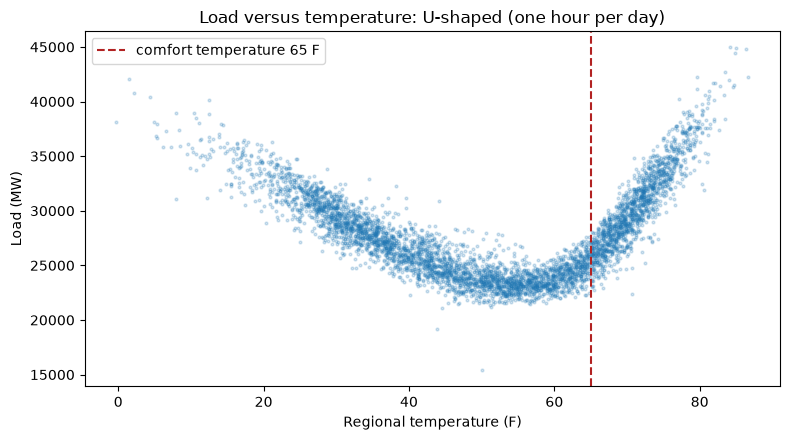

Correlation of load with temperature: 0.24 (linear) — misleading for a U-shape; with |T - 65F|: 0.32


In [11]:
sample = eda.iloc[::24]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(sample.wx_temp_f, sample[TARGET], s=4, alpha=0.2)
ax.axvline(COMFORT_TEMP_F, color="firebrick", ls="--", label=f"comfort temperature {COMFORT_TEMP_F} F")
ax.set(xlabel="Regional temperature (F)", ylabel="Load (MW)", title="Load versus temperature: U-shaped (one hour per day)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Correlation of load with temperature: {eda[TARGET].corr(eda.wx_temp_f):.2f} (linear) — "
      f"misleading for a U-shape; with |T - {COMFORT_TEMP_F}F|: {eda[TARGET].corr((eda.wx_temp_f - COMFORT_TEMP_F).abs()):.2f}")

**Load against temperature is U-shaped.** It's lowest around 50-65 F and goes up when it gets
colder (heating) or hotter (cooling). A plain linear temperature term would mostly cancel out,
so temperature is split into cooling degree hours (above 65 F) and heating degree hours (below
65 F). We also add heat index for humid heat, wind chill for windy cold, and the average
temperature over the past 24 and 72 hours, since buildings keep soaking up heat or cold during a
multi-day spell.

Weather matters because lagged load can't see a change coming. On the first hot day of a heat
wave, yesterday's load still looks like a mild day.

# 3. Modeling

## 3a. Features and chronological split

- **Load features:** lags at 1, 24 and 168 hours, plus the mean and standard deviation over the
  past 24 and 168 hours. The rolling windows are shifted by one hour so they only see the past.
- **Calendar features:** hour, day of week, month, weekend, year (for slow drift) and US federal
  holidays.
- **Weather features:** the four raw `wx_` columns plus the ones derived from the U-shape above.

Features are built on the whole series first, then split by time: the first 80% of rows for
training and the last 20% for test. Lags are allowed to reach across the split, since that's
history a real forecaster would have. The first rows don't have a full week of history, so
they're dropped.

In [12]:
feature_df = clean_df.copy()
feature_df[TARGET] = feature_df[TARGET].astype(float)

# Load history
for lag in LAGS:
    feature_df[f"lag_{lag}h"] = feature_df[TARGET].shift(lag)
for window in ROLLING_WINDOWS:
    shifted = feature_df[TARGET].shift(1)
    feature_df[f"rolling_mean_{window}h"] = shifted.rolling(window).mean()
    feature_df[f"rolling_std_{window}h"] = shifted.rolling(window).std()

# Calendar and holidays (padding covers the longest holiday-free stretch of the year)
feature_df["hour"] = feature_df.index.hour
feature_df["day_of_week"] = feature_df.index.dayofweek
feature_df["month"] = feature_df.index.month
feature_df["is_weekend"] = (feature_df.index.dayofweek >= 5).astype(int)
feature_df["year"] = feature_df.index.year
pad = pd.Timedelta(days=200)
holidays = USFederalHolidayCalendar().holidays(feature_df.index.min() - pad, feature_df.index.max() + pad)
normalized = feature_df.index.normalize()
feature_df["is_holiday"] = normalized.isin(holidays).astype(int)
feature_df["days_to_nearest_holiday"] = [
    int(np.abs(holidays.values - ts).min() / np.timedelta64(1, "D")) for ts in normalized.values
]

# Weather: degree hours split the U-shape into cooling and heating arms
t, rh, wind = feature_df.wx_temp_f.astype(float), feature_df.wx_rel_humidity.astype(float), feature_df.wx_wind_mph.astype(float)
feature_df["wx_cdh"] = (t - COMFORT_TEMP_F).clip(lower=0)
feature_df["wx_hdh"] = (COMFORT_TEMP_F - t).clip(lower=0)
# NWS heat index: Rothfusz regression with NWS humidity adjustments; NWS simple formula below 80 F
simple = 0.5 * (t + 61.0 + (t - 68.0) * 1.2 + rh * 0.094)
heat_index = (-42.379 + 2.04901523 * t + 10.14333127 * rh - 0.22475541 * t * rh
              - 0.00683783 * t**2 - 0.05481717 * rh**2 + 0.00122874 * t**2 * rh
              + 0.00085282 * t * rh**2 - 0.00000199 * t**2 * rh**2)
low_rh = (rh < 13) & (t >= 80) & (t <= 112)
heat_index = heat_index - np.where(low_rh, ((13 - rh) / 4) * np.sqrt(np.clip((17 - (t - 95).abs()) / 17, 0, None)), 0.0)
high_rh = (rh > 85) & (t >= 80) & (t <= 87)
heat_index = heat_index + np.where(high_rh, ((rh - 85) / 10) * ((87 - t) / 5), 0.0)
feature_df["wx_heat_index_f"] = np.where(((simple + t) / 2) >= 80, heat_index, simple)
# NWS (2001) wind chill, defined for T <= 50 F and wind > 3 mph; otherwise the air temperature
v16 = np.power(np.clip(wind, 0, None), 0.16)
feature_df["wx_wind_chill_f"] = np.where((t <= 50) & (wind > 3), 35.74 + 0.6215 * t - 35.75 * v16 + 0.4275 * t * v16, t)
for window in WEATHER_ROLLING_WINDOWS:
    feature_df[f"wx_temp_mean_{window}h"] = t.rolling(window).mean()

rows_before = len(feature_df)
feature_df = feature_df.dropna()
split_idx = int(len(feature_df) * TRAIN_FRACTION)
train_df, test_df = feature_df.iloc[:split_idx].copy(), feature_df.iloc[split_idx:].copy()
snapshot = feature_df.tail(SNAPSHOT_HOURS).copy()  # latest real history, seeds the final forecast
FEATURES = [c for c in train_df.columns if c != TARGET]

assert not train_df.select_dtypes(exclude="number").columns.tolist(), "non-numeric columns"
print(f"Train {train_df.shape} ({train_df.index.min()} to {train_df.index.max()}), test {test_df.shape} "
      f"({test_df.index.min()} to {test_df.index.max()}); {len(FEATURES)} features; {rows_before - len(feature_df)} warm-up rows dropped")
train_df.head()

Train (116179, 25) (2002-01-08 01:00:00 to 2015-04-10 19:00:00), test (29045, 25) (2015-04-10 20:00:00 to 2018-08-03 00:00:00); 24 features; 168 warm-up rows dropped


,PJME_MW,wx_temp_f,wx_dewpoint_f,wx_rel_humidity,wx_wind_mph,lag_1h,lag_24h,lag_168h,rolling_mean_24h,rolling_std_24h,...,is_weekend,year,is_holiday,days_to_nearest_holiday,wx_cdh,wx_hdh,wx_heat_index_f,wx_wind_chill_f,wx_temp_mean_24h,wx_temp_mean_72h
Datetime,,,,,,,,,,,,,,,,,,,,,
2002-01-08 01:00:00,29445.0,24.350,17.20,74.00,11.575,31187.0,26862.0,30393.0,33452.583333,4559.767709,...,0,2002,0,7,0.0,40.650,19.96300,13.378263,32.896875,33.140972
2002-01-08 02:00:00,28670.0,24.350,17.30,74.25,11.550,29445.0,25976.0,29265.0,33560.208333,4425.965952,...,0,2002,0,7,0.0,40.650,19.97475,13.391232,32.497917,33.074306
2002-01-08 03:00:00,28375.0,23.325,16.45,74.75,10.800,28670.0,25641.0,28357.0,33672.458333,4256.159403,...,0,2002,0,7,0.0,41.675,18.87075,12.513464,32.061458,32.987847
2002-01-08 04:00:00,28542.0,22.575,15.85,75.00,10.500,28375.0,25666.0,27899.0,33786.375000,4064.104959,...,0,2002,0,7,0.0,42.425,18.05750,11.749911,31.607292,32.888889
2002-01-08 05:00:00,29261.0,21.975,15.50,75.75,9.525,28542.0,26328.0,28057.0,33906.208333,3851.076461,...,0,2002,0,7,0.0,43.025,17.43275,11.597380,31.134375,32.785764


## 3b. Modeling decisions

- **Forecast 24 hours ahead from midnight.** PJM plans generation a day ahead, so what matters is
  the next 24 hourly values, made once a day. This was decided first because it sets how every
  model is scored and how a lag-based model has to produce its own inputs after the cutoff.
- **Split by time and use 50 shared cutoffs.** A random split would let the model learn from the
  future. Every model forecasts from the same 50 midnights with the same 24-hour horizon, so the
  scores can be compared directly.
- **Start with baselines.** Repeat-yesterday and repeat-last-week cost nothing. A model that
  can't beat them isn't worth using.
- **ETS as the classical model.** Additive trend and a 24-hour season. It can only hold one
  seasonal period, which is a known weakness given the three cycles in the EDA. SARIMAX was also
  tried in the pipeline and dropped: with a 24-hour season on hourly data it needed 2-11 GB of
  memory and minutes per fit, and still ended up around 100% MAPE.
- **LightGBM as the ML model.** It picks up the nonlinear effects the EDA showed (the daily shape
  changing with the season, the U-shaped temperature curve) without hand-written interaction
  terms, and it trains in seconds. Its settings are chosen by hand rather than tuned, so the
  comparison is about the type of model and not about how much tuning each one got.
- **With and without weather.** The same LightGBM is trained twice, and the only difference is
  the `wx_` columns. The gap between them is what weather is worth.
- **Recursive vs. direct.** The recursive model predicts one hour, feeds that prediction back in
  as a lag, and repeats, so errors can build up over the day. The direct model is a single model
  that takes `lead_hour` as an input. Its load features stay fixed at the cutoff, while the
  calendar and weather features match the hour being forecast. Comparing the two shows whether
  that error build-up matters here.
- **MAPE as the main metric.** It's a percentage, so it's easy to explain to an operations team.
  MAE and RMSE (in MW) and MASE (MAE divided by the average 24-hour change in the training load)
  are reported too. The champion is picked on validation MAPE, never on the test results.

**A note on weather:** the models are given the actual observed weather for the hours they
forecast. That makes this a best case with perfect weather information, not the accuracy you'd
get from a real weather forecast.

## 3c. Shared forecasting code

These functions are used by every model, at every cutoff, in validation, in test and in the
final forecast, so they're defined once here.

In [13]:
def weather_columns(columns) -> list[str]:
    """Weather feature columns (the wx_ prefix), order preserved."""
    return [c for c in columns if c.startswith(WEATHER_PREFIX)]


def mape(actual: pd.Series, predicted: pd.Series) -> float:
    """Mean absolute percentage error, in percent."""
    a, p = actual.to_numpy(dtype=float), predicted.to_numpy(dtype=float)
    return float(np.mean(np.abs((a - p) / a)) * 100)


def select_cv_origins(index: pd.DatetimeIndex, n_windows: int, horizon: int) -> list[pd.Timestamp]:
    """Up to n_windows evenly spaced midnight cutoffs, each with a complete horizon."""
    usable = index[: len(index) - horizon + 1]
    usable = usable[(usable.hour == 0) & (usable.minute == 0)]
    positions = np.linspace(0, len(usable) - 1, min(n_windows, len(usable))).astype(int)
    return list(usable[positions])


def federal_holidays(start: pd.Timestamp, end: pd.Timestamp) -> pd.DatetimeIndex:
    """US federal holidays padded 200 days either side, like the feature step."""
    pad = pd.Timedelta(days=200)
    return USFederalHolidayCalendar().holidays(start=start - pad, end=end + pad)


def build_feature_row(buffer: pd.Series, ts: pd.Timestamp, holidays: pd.DatetimeIndex) -> dict[str, Any]:
    """Load-history, calendar and holiday features for hour ts, read from a load buffer."""
    row: dict[str, Any] = {}
    for lag in LAGS:
        row[f"lag_{lag}h"] = buffer.get(ts - pd.Timedelta(hours=lag), np.nan)
    for window in ROLLING_WINDOWS:
        vals = pd.Series([buffer.get(ts - pd.Timedelta(hours=h), np.nan) for h in range(1, window + 1)])
        complete = not vals.isna().any()
        row[f"rolling_mean_{window}h"] = vals.mean() if complete else np.nan
        row[f"rolling_std_{window}h"] = vals.std() if complete else np.nan
    row.update(hour=ts.hour, day_of_week=ts.dayofweek, month=ts.month,
               is_weekend=int(ts.dayofweek >= 5), year=ts.year)
    day = ts.normalize()
    row["is_holiday"] = int(day in holidays)
    row["days_to_nearest_holiday"] = int(np.abs(holidays.values - np.datetime64(day)).min() / np.timedelta64(1, "D"))
    return row


def recursive_forecast(model: Any, history: pd.Series, horizon: int, columns: list[str],
                       exog: pd.DataFrame | None = None) -> pd.Series:
    """Predict one hour at a time, appending each prediction to the lag buffer."""
    buffer = history.copy()
    holidays = federal_holidays(buffer.index.min(), buffer.index.max() + pd.Timedelta(hours=horizon))
    predictions = []
    next_ts = buffer.index[-1] + pd.Timedelta(hours=1)
    for _ in range(horizon):
        row = build_feature_row(buffer, next_ts, holidays)
        if exog is not None:
            row.update(exog.loc[next_ts].to_dict())  # known-in-advance weather for that hour
        pred = float(model.predict(pd.DataFrame([row], index=[next_ts])[columns])[0])
        predictions.append(pred)
        buffer.loc[next_ts] = pred
        next_ts += pd.Timedelta(hours=1)
    return pd.Series(predictions, index=buffer.index[-horizon:])


def target_calendar(index: pd.DatetimeIndex) -> pd.DataFrame:
    """Calendar and holiday features at each forecast hour's valid time (direct model)."""
    frame = pd.DataFrame(index=np.arange(len(index)))
    frame["hour"] = index.hour
    frame["day_of_week"] = index.dayofweek
    frame["month"] = index.month
    frame["is_weekend"] = (index.dayofweek >= 5).astype(int)
    frame["year"] = index.year
    normalized = index.normalize().values
    holiday_index = USFederalHolidayCalendar().holidays(index.min().normalize() - pd.Timedelta(days=200),
                                                        index.max().normalize() + pd.Timedelta(days=200))
    hv = holiday_index.values
    pos = np.searchsorted(hv, normalized)
    left, right = np.maximum(pos - 1, 0), np.minimum(pos, len(hv) - 1)
    distance = np.minimum(np.abs(normalized - hv[left]), np.abs(normalized - hv[right])) // np.timedelta64(1, "D")
    frame["is_holiday"] = index.normalize().isin(holiday_index).astype(int)
    frame["days_to_nearest_holiday"] = distance.astype(int)
    return frame


def direct_forecast(model: Any, frame: pd.DataFrame, model_columns: list[str], origin: pd.Timestamp) -> pd.Series:
    """Forecast every lead from the same pre-cutoff load history (direct model)."""
    history = frame[TARGET].loc[: origin - pd.Timedelta(hours=1)]
    holidays = federal_holidays(history.index.min(), origin + pd.Timedelta(hours=HORIZON))
    wx_cols = weather_columns(model_columns)
    index = pd.date_range(origin, periods=HORIZON, freq="h")
    rows = []
    for lead, valid_time in enumerate(index, start=1):
        row = build_feature_row(history, origin, holidays)
        row.update(target_calendar(pd.DatetimeIndex([valid_time])).iloc[0].to_dict())
        if wx_cols:
            row.update(frame.loc[valid_time, wx_cols].to_dict())
        row["lead_hour"] = lead
        rows.append(row)
    return pd.Series(model.predict(pd.DataFrame(rows, index=index)[model_columns]), index=index)

In [14]:
def fit_model(spec: dict[str, Any], frame: pd.DataFrame, columns: list[str]) -> Any:
    """Fit one model on a training partition (None for the naive baselines)."""
    if spec["type"] == "seasonal_naive":
        return None
    if spec["type"] == "ets":
        return ETSModel(frame[TARGET], trend="add", seasonal="add", seasonal_periods=24).fit(disp=False)
    model = LGBMRegressor(**spec["params"])
    if spec["type"] == "gbm":
        return model.fit(frame[columns], frame[TARGET])
    # Direct: stack (cutoff, lead) pairs at a 6-hour cutoff stride; load features at the cutoff,
    # calendar and weather features at the lead's valid time.
    positions = np.arange(0, len(frame) - HORIZON, spec["stride_hours"])
    base = frame[columns].iloc[positions].reset_index(drop=True)
    wx_cols = weather_columns(columns)
    x_parts, y_parts = [], []
    for lead in range(1, HORIZON + 1):
        targets = positions + lead
        X = base.copy()
        calendar = target_calendar(frame.index.take(targets))
        for column in calendar.columns:
            X[column] = calendar[column].to_numpy()
        if wx_cols:
            X.loc[:, wx_cols] = frame[wx_cols].iloc[targets].to_numpy()
        X["lead_hour"] = lead
        x_parts.append(X[columns + ["lead_hour"]])
        y_parts.append(frame[TARGET].iloc[targets].reset_index(drop=True))
    return model.fit(pd.concat(x_parts, ignore_index=True), pd.concat(y_parts, ignore_index=True))


def forecast_metrics(predictions: pd.DataFrame, scale: float) -> dict[str, float]:
    """Pooled hourly MAE, RMSE, MAPE and MASE."""
    error = predictions.actual - predictions.predicted
    mae = float(error.abs().mean())
    return {"mae": mae, "rmse": float(np.sqrt((error**2).mean())),
            "mape": mape(predictions.actual, predictions.predicted), "mase": mae / scale}


def evaluate_origins(model: Any, model_type: str, df: pd.DataFrame, columns: list[str],
                     origins: list[pd.Timestamp], scale_history: pd.Series,
                     season_length: int = 168) -> tuple[dict[str, Any], pd.DataFrame]:
    """Forecast 24 hours from every cutoff, then score: pooled metrics, per-day MAPE, season/holiday errors."""
    if scale_history.index[-1] >= min(origins):
        raise ValueError("MASE scale history must precede every cutoff")
    y = df[TARGET]
    wx = weather_columns(columns)
    frames = []
    for origin in origins:
        idx = pd.date_range(origin, periods=HORIZON, freq="h")
        history = y.loc[: origin - pd.Timedelta(hours=1)]
        if model_type == "seasonal_naive":
            values = np.resize(history.tail(season_length).to_numpy(), HORIZON)
        elif model_type == "ets":
            # Fixed fitted parameters; state re-smoothed on all load observed before the cutoff.
            src = model.model
            if pd.Timestamp(src.data.dates[-1]) >= origin:
                raise ValueError("ETS must be fitted strictly before every cutoff")
            refreshed = ETSModel(y.loc[pd.Timestamp(src.data.dates[0]): origin - pd.Timedelta(hours=1)],
                                 error=src.error, trend=src.trend, damped_trend=src.damped_trend,
                                 seasonal=src.seasonal, seasonal_periods=src.seasonal_periods,
                                 initialization_method="estimated").smooth(model.params)
            values = np.asarray(refreshed.forecast(HORIZON))
        elif model_type == "gbm_direct":
            values = direct_forecast(model, df, columns, origin).to_numpy()
        else:
            values = recursive_forecast(model, history, HORIZON, columns, exog=df[wx] if wx else None).to_numpy()
        frames.append(pd.DataFrame({"actual": y.reindex(idx).to_numpy(), "predicted": values, "origin": origin}, index=idx))
    predictions = pd.concat(frames)
    if predictions[["actual", "predicted"]].isna().any().any():
        raise ValueError("Incomplete evaluation predictions")

    scale = float(scale_history.diff(24).abs().mean())
    metrics: dict[str, Any] = forecast_metrics(predictions, scale)
    scores = [mape(g.actual, g.predicted) for _, g in predictions.groupby("origin")]
    metrics.update(mape_mean=float(np.mean(scores)), mape_std=float(np.std(scores)), n_windows=len(scores))
    predictions["season"] = predictions.index.month.map(SEASONS)
    test_holidays = USFederalHolidayCalendar().holidays(predictions.index.min().normalize(), predictions.index.max().normalize())
    predictions["holiday"] = predictions.index.normalize().isin(test_holidays).astype(int)
    metrics["errors_by"] = {
        field: {str(label): {**forecast_metrics(g, scale), "n_hours": len(g)} for label, g in predictions.groupby(field)}
        for field in ("season", "holiday")
    }
    return metrics, predictions

## 3d. Train, validate and test

The last 20% of the training period is held back for validation. Each model is fitted once on
the training data before the first validation cutoff and scored on 50 validation days. It's then
refitted on the full training set and scored on 50 days spread across the test period.

The model parameters don't change within a period. Only the load history (and the ETS state) is
updated at each cutoff. The champion is the candidate (ETS or one of the recursive LightGBMs)
with the lowest validation MAPE. The naive baselines and the direct model are there for
comparison only.

In [15]:
%%time
validation_index = train_df.index[max(int(len(train_df) * 0.8), max(LAGS + ROLLING_WINDOWS)):]
val_origins = select_cv_origins(validation_index, N_WINDOWS, HORIZON)
fit_df = train_df.loc[train_df.index < val_origins[0]]
test_origins = select_cv_origins(test_df.index, N_WINDOWS, HORIZON)
full_df = pd.concat([train_df, test_df]).sort_index()

results: dict[str, dict[str, Any]] = {}
for spec in MODELS:
    columns = [c for c in FEATURES if spec.get("use_weather", True) or not c.startswith(WEATHER_PREFIX)]
    eval_columns = columns + ["lead_hour"] if spec["type"] == "gbm_direct" else columns
    season_length = spec.get("season_length", 168)

    val_model = fit_model(spec, fit_df, columns)
    val_metrics, val_pred = evaluate_origins(val_model, spec["type"], train_df, eval_columns, val_origins,
                                             fit_df[TARGET], season_length)
    final_model = fit_model(spec, train_df, columns)
    test_metrics, test_pred = evaluate_origins(final_model, spec["type"], full_df, eval_columns, test_origins,
                                               train_df[TARGET], season_length)
    results[spec["name"]] = {"spec": spec, "columns": eval_columns, "model": final_model,
                             "val": val_metrics, "val_pred": val_pred, "test": test_metrics, "test_pred": test_pred}
    print(f"{spec['name']:15s} validation MAPE {val_metrics['mape_mean']:.2f}%  test MAPE {test_metrics['mape_mean']:.2f}%")

candidates = [n for n, r in results.items() if r["spec"]["status"] == "candidate"]
champion = min(candidates, key=lambda n: results[n]["val"]["mape_mean"])
print(f"\nValidation fit {fit_df.index[0]} to {fit_df.index[-1]} ({len(fit_df):,} rows); "
      f"cutoffs {val_origins[0].date()} to {val_origins[-1].date()}")
print(f"Test cutoffs {test_origins[0].date()} to {test_origins[-1].date()}; champion by validation MAPE: {champion}")

daily_naive     validation MAPE 7.22%  test MAPE 6.89%
weekly_naive    validation MAPE 9.34%  test MAPE 10.61%


ets             validation MAPE 6.64%  test MAPE 7.11%
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000772 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4440
[LightGBM] [Info] Number of data points in the train set: 92951, number of used features: 24
[LightGBM] [Info] Start training from score 32490.373277


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000798 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4444
[LightGBM] [Info] Number of data points in the train set: 116179, number of used features: 24
[LightGBM] [Info] Start training from score 32325.560665


gbm             validation MAPE 2.83%  test MAPE 2.72%


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002608 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4465
[LightGBM] [Info] Number of data points in the train set: 371712, number of used features: 25
[LightGBM] [Info] Start training from score 32489.224835


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002326 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4469
[LightGBM] [Info] Number of data points in the train set: 464640, number of used features: 25
[LightGBM] [Info] Start training from score 32325.680796


gbm_direct      validation MAPE 2.98%  test MAPE 2.75%
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000473 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1898
[LightGBM] [Info] Number of data points in the train set: 92951, number of used features: 14
[LightGBM] [Info] Start training from score 32490.373277


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000548 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1901
[LightGBM] [Info] Number of data points in the train set: 116179, number of used features: 14
[LightGBM] [Info] Start training from score 32325.560665


gbm_no_weather  validation MAPE 4.29%  test MAPE 4.33%

Validation fit 2002-01-08 01:00:00 to 2012-08-15 23:00:00 (92,951 rows); cutoffs 2012-08-16 to 2015-04-09
Test cutoffs 2015-04-11 to 2018-08-02; champion by validation MAPE: gbm
CPU times: user 4min 41s, sys: 36.7 s, total: 5min 18s
Wall time: 4min 39s


# 4. Evaluation

This is the held-out test. Every model forecasts the same 50 test days (1,200 hours), 24 hours
ahead from midnight. MAE and RMSE are in MW and MAPE is in percent. MASE divides by the average
24-hour change in the training data, which stays fixed. Keep in mind that the weather models are
given perfect weather information.

In [16]:
METRICS = ["mae", "rmse", "mape", "mase"]
test_summary = pd.DataFrame({
    n: {"status": r["spec"]["status"], **{m: r["test"][m] for m in METRICS},
        "test_mape_mean": r["test"]["mape_mean"], "cv_mape_mean": r["val"]["mape_mean"],
        "n_windows_scored": r["test"]["n_windows"]}
    for n, r in results.items()
}).T
results_table = pd.DataFrame({"Validation MAPE (%)": test_summary.cv_mape_mean.astype(float),
                              "Test MAPE (%)": test_summary.test_mape_mean.astype(float)}).round(2)
display(test_summary.sort_values("test_mape_mean"))

,status,mae,rmse,mape,mase,test_mape_mean,cv_mape_mean,n_windows_scored
gbm,candidate,856.343125,1147.487159,2.717414,0.394524,2.717414,2.833136,50
gbm_direct,benchmark,854.50752,1110.574934,2.751087,0.393678,2.751087,2.981093,50
gbm_no_weather,candidate,1429.18404,2018.932012,4.331267,0.658436,4.331267,4.294811,50
daily_naive,baseline,2147.235,2857.692844,6.893839,0.989247,6.893839,7.219614,50
ets,candidate,2182.118794,2819.229617,7.106003,1.005318,7.106003,6.636019,50
weekly_naive,baseline,3436.943333,4827.816703,10.606142,1.583425,10.606142,9.336918,50


**Which way are the misses?** Under-forecasting is the expensive one: the utility has to buy
peaking power at short notice. Over-forecasting means paying for capacity that sits unused. Bias
here is the average of (actual - forecast), so a positive number means the model forecasts too
low on average.

In [17]:
bias = pd.DataFrame({
    n: {"bias_mw": float((r["test_pred"].actual - r["test_pred"].predicted).mean()),
        "share_hours_under_forecast": float((r["test_pred"].actual > r["test_pred"].predicted).mean()),
        "worst_under_forecast_mw": float((r["test_pred"].actual - r["test_pred"].predicted).max()),
        "worst_over_forecast_mw": float((r["test_pred"].predicted - r["test_pred"].actual).max())}
    for n, r in results.items()
}).T
bias.round(3)

,bias_mw,share_hours_under_forecast,worst_under_forecast_mw,worst_over_forecast_mw
daily_naive,-486.815,0.428,9619.000,10230.000
weekly_naive,220.578,0.473,19120.000,16981.000
ets,-180.912,0.458,10150.326,7856.619
gbm,-134.345,0.428,5741.763,2839.872
gbm_direct,-322.667,0.353,4188.267,4145.431
gbm_no_weather,-40.024,0.401,9158.645,4376.761


In [18]:
# Test MAPE by season and on holidays (error by hour of day is in 5b)
for field in ("season", "holiday"):
    grouped = pd.DataFrame([{"model": n, field: label, **m}
                            for n, r in results.items() for label, m in r["test"]["errors_by"][field].items()])
    if field == "holiday":
        grouped[field] = grouped[field].astype(int)
    display(grouped.pivot(index=field, columns="model", values="mape").round(2))

model,daily_naive,ets,gbm,gbm_direct,gbm_no_weather,weekly_naive
season,,,,,,
autumn,5.13,7.53,2.80,2.61,4.02,10.10
spring,6.54,6.90,3.07,3.09,3.98,7.97
summer,6.54,6.49,2.34,2.51,4.47,12.67
winter,10.00,7.75,2.65,2.78,5.01,12.00


model,daily_naive,ets,gbm,gbm_direct,gbm_no_weather,weekly_naive
holiday,,,,,,
0,6.83,7.19,2.67,2.67,4.25,10.36
1,9.93,2.83,4.88,6.51,8.47,22.86


## 4b. Where does weather help?

The weather and no-weather LightGBM test predictions are lined up on the same cutoff and the same
forecast hour. Both models have the same settings, cutoffs and forecasting code, so the only
difference is the `wx_` inputs. A positive gain means weather helped. None of this is used to
choose features or tune anything.

In [19]:
def summarize_pair(group: pd.DataFrame) -> dict[str, Any]:
    """Weather vs no-weather MAE and MAPE gains for one group of paired hours."""
    wx_mae, base_mae = float(group.weather_abs_error_mw.mean()), float(group.no_weather_abs_error_mw.mean())
    return {"n_hours": len(group), "n_days": group.index.get_level_values("origin").nunique(),
            "weather_mae_mw": wx_mae, "no_weather_mae_mw": base_mae, "mae_gain_mw": base_mae - wx_mae,
            "mae_reduction_pct": (base_mae - wx_mae) / base_mae * 100, "mape_gain_pp": float(group.mape_gain_pp.mean())}


# Pair the two models' test predictions on (cutoff, forecast hour)
wx_pred, base_pred = (results[n]["test_pred"].assign(timestamp=results[n]["test_pred"].index)
                      .set_index(["origin", "timestamp"]).sort_index() for n in ("gbm", "gbm_no_weather"))
assert wx_pred.index.equals(base_pred.index) and wx_pred.actual.equals(base_pred.actual)
paired = wx_pred[["actual", "season", "holiday"]].copy()
paired["weather_abs_error_mw"] = (wx_pred.actual - wx_pred.predicted).abs()
paired["no_weather_abs_error_mw"] = (base_pred.actual - base_pred.predicted).abs()
paired["mae_gain_mw"] = paired.no_weather_abs_error_mw - paired.weather_abs_error_mw
paired["mape_gain_pp"] = paired.mae_gain_mw / paired.actual * 100
daily_comparison = paired.groupby(level="origin").agg(
    weather_mae_mw=("weather_abs_error_mw", "mean"), no_weather_mae_mw=("no_weather_abs_error_mw", "mean"),
    mae_gain_mw=("mae_gain_mw", "mean"), mape_gain_pp=("mape_gain_pp", "mean"))
overall = summarize_pair(paired)
days_improved = int((daily_comparison.mae_gain_mw > 0).sum())
days_worse = int((daily_comparison.mae_gain_mw < 0).sum())
holiday_days = paired[paired.holiday == 1].index.get_level_values("origin").nunique()
assert np.isclose(overall["mae_gain_mw"], results["gbm_no_weather"]["test"]["mae"] - results["gbm"]["test"]["mae"])

season_comparison = pd.DataFrame({s: summarize_pair(g) for s, g in paired.groupby("season")}).T
display(season_comparison[["n_days", "weather_mae_mw", "no_weather_mae_mw", "mae_gain_mw", "mae_reduction_pct"]].astype(float).round(1))
print("Five days where weather helped least (negative gain = weather was worse):")
display(daily_comparison.sort_values("mae_gain_mw").head(5).round(1))

season_gains = season_comparison.mae_gain_mw.sort_values(ascending=False)
display(Markdown(
    f"Weather reduces daily MAE on **{days_improved} of {overall['n_days']} sampled days** "
    f"(worse on {days_worse}, tied on {overall['n_days'] - days_improved - days_worse}). Overall MAE improves by "
    f"**{overall['mae_gain_mw']:.2f} MW** and MAPE by **{overall['mape_gain_pp']:.2f} percentage points**. "
    "Seasonal MAE gains: " + "; ".join(f"{s}: {v:.2f} MW" for s, v in season_gains.items()) +
    f". Holiday estimates cover only **{holiday_days} sampled holiday day(s)**."
))

,n_days,weather_mae_mw,no_weather_mae_mw,mae_gain_mw,mae_reduction_pct
autumn,12.0,868.2,1283.7,415.5,32.4
spring,14.0,872.4,1160.9,288.5,24.8
summer,14.0,836.8,1692.0,855.1,50.5
winter,10.0,846.9,1611.5,764.5,47.4


Five days where weather helped least (negative gain = weather was worse):


,weather_mae_mw,no_weather_mae_mw,mae_gain_mw,mape_gain_pp
origin,,,,
2017-06-08,833.0,661.3,-171.7,-0.5
2015-10-25,452.0,323.9,-128.1,-0.5
2018-05-19,447.7,337.2,-110.4,-0.4
2016-10-04,844.2,810.6,-33.6,-0.0
2016-08-16,1187.5,1170.8,-16.7,-0.1


Weather reduces daily MAE on **45 of 50 sampled days** (worse on 5, tied on 0). Overall MAE improves by **572.84 MW** and MAPE by **1.61 percentage points**. Seasonal MAE gains: summer: 855.15 MW; winter: 764.54 MW; autumn: 415.48 MW; spring: 288.49 MW. Holiday estimates cover only **1 sampled holiday day(s)**.

# 5. Final Forecast Generation

This section produces the numbers and figures used in the executive summary and the
presentation, all from the evaluation results above.

## 5a. Held-out model comparison (presentation figure)

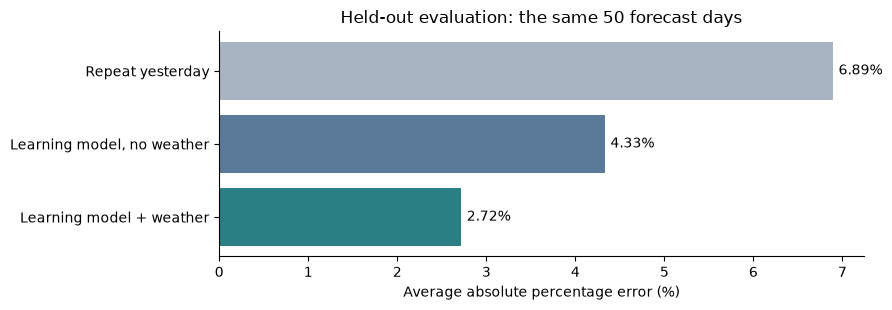

Repeat yesterday              6.8938
Learning model, no weather    4.3313
Learning model + weather      2.7174
Weather vs no weather: 37.26% lower test MAPE; weather vs repeat yesterday: 60.6% lower


In [20]:
labels = {"daily_naive": "Repeat yesterday", "gbm_no_weather": "Learning model, no weather", "gbm": "Learning model + weather"}
test_mape = pd.Series({lab: results[name]["test"]["mape"] for name, lab in labels.items()})
reduction = (test_mape.iloc[1] - test_mape.iloc[2]) / test_mape.iloc[1]

fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.barh(test_mape.index[::-1], test_mape.values[::-1], color=["#2a7f84", "#5b7a99", "#a9b4c2"])
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in test_mape.values[::-1]], padding=4)
ax.set_xlabel("Average absolute percentage error (%)")
ax.set_title(f"Held-out evaluation: the same {len(test_origins)} forecast days")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "heldout_model_comparison.png", dpi=200)
plt.show()
print(test_mape.round(4).to_string())
print(f"Weather vs no weather: {reduction:.2%} lower test MAPE; "
      f"weather vs repeat yesterday: {1 - test_mape.iloc[2] / test_mape.iloc[0]:.1%} lower")

## 5b. Forecast with a 90% range

The ranges come from the weather LightGBM's 1,200 absolute errors on the validation days (from
3d). They're then applied as-is to the test predictions, so no test error is used to set them.

- **Constant band:** one width for every hour, the 90th percentile of all validation errors.
- **Per-hour band:** a separate 90th percentile for each hour of the day (50 validation errors
  each). Overnight the grid is mostly base load and the misses are small. In the afternoon air
  conditioning drives demand and the misses are about three times bigger. So a constant band is
  too wide at night and too narrow at the 1-6 p.m. peak.

Some caveats. The ranges reuse the validation period that also picked the model, and hours in the
same day are correlated, so the coverage numbers describe what happened rather than guarantee
anything. Every forecast starts at midnight, so the early-morning hours are also the shortest
lead times, and this setup can't tell those two effects apart. The example day is simply the
last test cutoff. It wasn't picked for looking good.

Validation fit rows: 92,951; validation hours: 1,200 (2012-08-16 00:00:00 to 2015-04-09 23:00:00)
Constant band: +/-1,927.7 MW every hour; test coverage 90.8%; 1-6 p.m. coverage 81.3%
Per-hour band: +/-539 to +/-3,188 MW (average +/-1,907); test coverage 92.9%; 1-6 p.m. coverage 93.3%


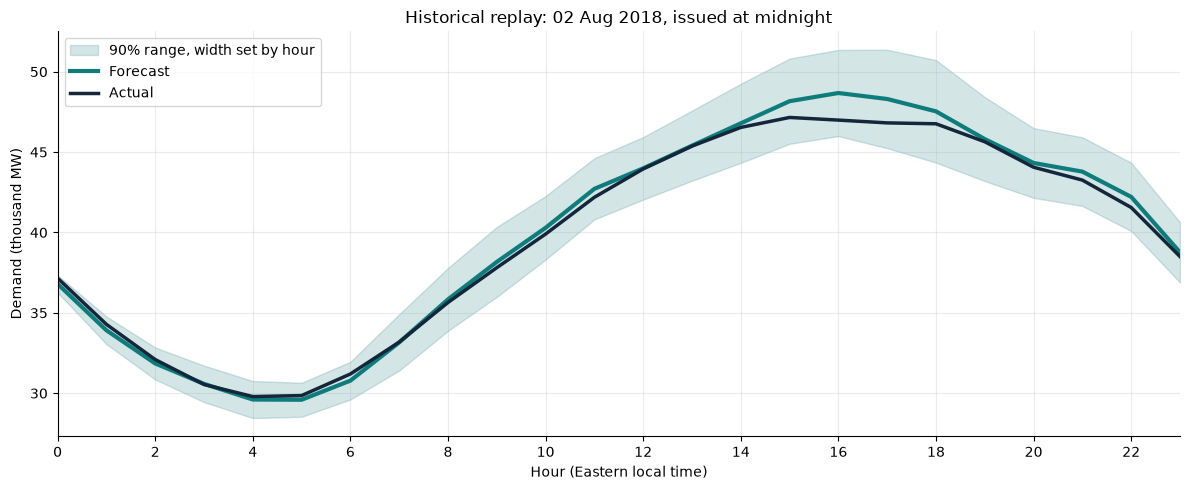

Example day 2018-08-02: forecast peak 48,674 MW at 16:00; actual peak 47,154 MW; 100% of hours inside the band (+/-1,153 MW at 4 a.m., +/-2,681 MW at 4 p.m.)


In [21]:
val_pred = results["gbm"]["val_pred"]
test_pred = results["gbm"]["test_pred"]
val_err = val_pred.assign(abs_err=(val_pred.actual - val_pred.predicted).abs(), hour=val_pred.index.hour)
test_err = test_pred.assign(abs_err=(test_pred.actual - test_pred.predicted).abs(), hour=test_pred.index.hour)

half_width = float(np.quantile(val_err.abs_err, 0.9, method="higher"))
hour_half_width = val_err.groupby("hour").abs_err.quantile(0.9, interpolation="higher")
test_err["hour_half_width"] = test_err.hour.map(hour_half_width)
test_err["inside_constant_band"] = test_err.abs_err <= half_width
test_err["inside_hour_band"] = test_err.abs_err <= test_err.hour_half_width
coverage = float(test_err.inside_constant_band.mean())
hour_coverage = float(test_err.inside_hour_band.mean())
peak_hours = test_err.hour.between(13, 18)
print(f"Validation fit rows: {len(fit_df):,}; validation hours: {len(val_pred):,} ({val_pred.index.min()} to {val_pred.index.max()})")
print(f"Constant band: +/-{half_width:,.1f} MW every hour; test coverage {coverage:.1%}; "
      f"1-6 p.m. coverage {test_err.loc[peak_hours, 'inside_constant_band'].mean():.1%}")
print(f"Per-hour band: +/-{hour_half_width.min():,.0f} to +/-{hour_half_width.max():,.0f} MW "
      f"(average +/-{hour_half_width.mean():,.0f}); test coverage {hour_coverage:.1%}; "
      f"1-6 p.m. coverage {test_err.loc[peak_hours, 'inside_hour_band'].mean():.1%}")

# Example day (presentation figure): the last test cutoff with the per-hour band
last_origin = test_err.origin.max()
day = test_err[test_err.origin == last_origin]
hours = day.index.hour
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(hours, (day.predicted - day.hour_half_width) / 1000, (day.predicted + day.hour_half_width) / 1000,
                color="#2a7f84", alpha=0.2, label="90% range, width set by hour")
ax.plot(hours, day.predicted / 1000, color="#0f7c7c", lw=3, label="Forecast")
ax.plot(hours, day.actual / 1000, color="#13263a", lw=2.5, label="Actual")
ax.set(xlim=(0, 23), xticks=range(0, 24, 2), xlabel="Hour (Eastern local time)", ylabel="Demand (thousand MW)",
       title=f"Historical replay: {pd.Timestamp(last_origin):%d %b %Y}, issued at midnight")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "forecast_with_hour_band.png", dpi=200)
plt.show()
print(f"Example day {pd.Timestamp(last_origin):%Y-%m-%d}: forecast peak {day.predicted.max():,.0f} MW at "
      f"{day.predicted.idxmax():%H:%M}; actual peak {day.actual.max():,.0f} MW; {day.inside_hour_band.mean():.0%} of hours inside "
      f"the band (+/-{hour_half_width.loc[4]:,.0f} MW at 4 a.m., +/-{hour_half_width.loc[16]:,.0f} MW at 4 p.m.)")

## 5c. A real 24-hour forecast past the end of the data

The weather model can't forecast the actual future, because it needs future weather and there's
no weather forecast feed here. So, like the pipeline's serving endpoint, this uses the no-weather
LightGBM, starting from the last 168 hours of real load.

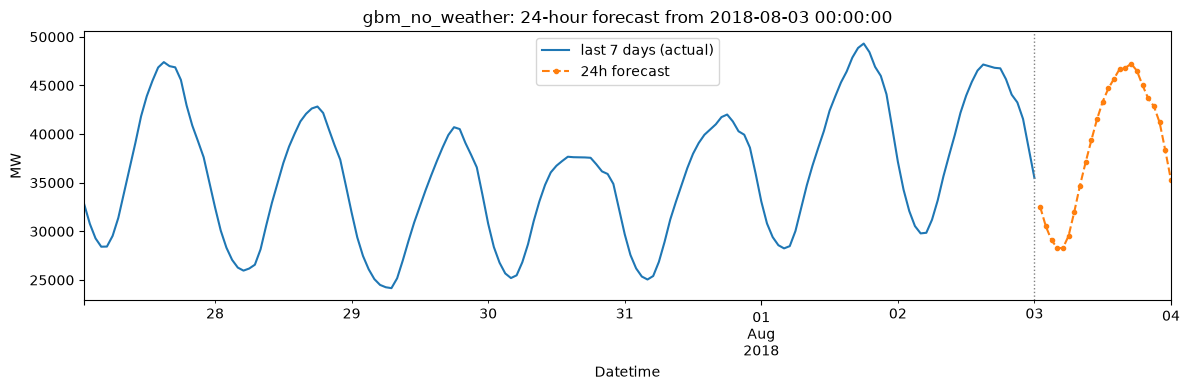

Datetime,2018-08-03 01:00:00,2018-08-03 02:00:00,2018-08-03 03:00:00,2018-08-03 04:00:00,2018-08-03 05:00:00,2018-08-03 06:00:00,2018-08-03 07:00:00,2018-08-03 08:00:00,2018-08-03 09:00:00,2018-08-03 10:00:00,...,2018-08-03 15:00:00,2018-08-03 16:00:00,2018-08-03 17:00:00,2018-08-03 18:00:00,2018-08-03 19:00:00,2018-08-03 20:00:00,2018-08-03 21:00:00,2018-08-03 22:00:00,2018-08-03 23:00:00,2018-08-04 00:00:00
forecast_mw,32533.0,30528.0,29087.0,28302.0,28273.0,29538.0,31995.0,34709.0,37107.0,39367.0,...,46723.0,46818.0,47231.0,46521.0,45018.0,43665.0,42851.0,41193.0,38315.0,35254.0


In [22]:
serving_name = "gbm_no_weather" if weather_columns(results[champion]["columns"]) else champion
forecast = recursive_forecast(results[serving_name]["model"], snapshot[TARGET], HORIZON, results[serving_name]["columns"])
fig, ax = plt.subplots()
snapshot[TARGET].tail(24 * 7).plot(ax=ax, label="last 7 days (actual)")
forecast.plot(ax=ax, label="24h forecast", linestyle="--", marker="o", markersize=3)
ax.axvline(snapshot.index[-1], color="gray", linestyle=":", linewidth=1)
ax.set_ylabel("MW")
ax.set_title(f"{serving_name}: 24-hour forecast from {snapshot.index[-1]}")
ax.legend()
plt.tight_layout()
plt.show()
forecast.to_frame("forecast_mw").to_csv(OUTPUT_DIR / "next_24h_forecast.csv")
forecast.round(0).to_frame("forecast_mw").T

## 5d. Summary and limits

Validation parameters are fitted once before the validation period, and the final parameters once
on all the training data. The ETS state and the LightGBM lag inputs update at each cutoff.

Fifty sampled days don't cover every test day, and the holiday comparison rests on very few days.
The weather results use observed weather, so they're a best case. Before this could be deployed,
it would need a second test using the weather forecasts that were actually available at each
cutoff.

In [23]:
wx, no_wx = results["gbm"]["test"]["mape"], results["gbm_no_weather"]["test"]["mape"]
display(Markdown(
    f"**Champion (lowest validation MAPE): `{champion}`.** Test MAPE {wx:.2f}% with weather versus "
    f"{no_wx:.2f}% without ({(no_wx - wx) / no_wx * 100:.1f}% relative reduction; perfect weather information). "
    f"Repeat-yesterday baseline: {results['daily_naive']['test']['mape']:.2f}%."
))
display(results_table)
summary = {
    "champion": champion,
    "models": {n: {"cv_mape_mean": r["val"]["mape_mean"], "test_mape_mean": r["test"]["mape_mean"],
                   **{m: r["test"][m] for m in METRICS}} for n, r in results.items()},
    "weather_relative_reduction": reduction, "half_width_mw": half_width, "test_coverage": coverage,
    "hour_band_test_coverage": hour_coverage,
    "test_cutoffs": [str(o) for o in test_origins],
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
results_table.to_csv(OUTPUT_DIR / "results_table.csv")
for name, r in results.items():
    r["test_pred"].to_csv(OUTPUT_DIR / f"{name}_test_predictions.csv")
print(f"Saved outputs to {OUTPUT_DIR}/")

**Champion (lowest validation MAPE): `gbm`.** Test MAPE 2.72% with weather versus 4.33% without (37.3% relative reduction; perfect weather information). Repeat-yesterday baseline: 6.89%.

,Validation MAPE (%),Test MAPE (%)
daily_naive,7.22,6.89
weekly_naive,9.34,10.61
ets,6.64,7.11
gbm,2.83,2.72
gbm_direct,2.98,2.75
gbm_no_weather,4.29,4.33


Saved outputs to outputs/


In [24]:
# Download everything in outputs/ as one zip (Colab only).
if IN_COLAB:
    from google.colab import files
    shutil.make_archive("pjm_outputs", "zip", OUTPUT_DIR)
    files.download("pjm_outputs.zip")